In [1]:
title = "# Introduction to Bayesian statistics: exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)
import numpy as np
import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Introduction to Bayesian statistics: exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

In [2]:
import matplotlib.pyplot as plt
import scipy.stats
import emcee
import corner


# Exercise 1

- Implement your own version of the line-fitting procedure, using the same data.
- Now try it with the data in `lectures/data/linear_fits/data_1.txt`
    - First plot the data. What has changed?
    - Try the same model and likelihood on the new data. You might want to adjust the prior on $m$ and $b$ for this new data set.
    - What if you use the provided uncertainty per data point $\sigma_{y_i}$, instead of assuming a constant variance $\sigma_y$ for all data points?
    - Instead use the actual likelihood of the data:
\begin{align}
    \mu(x) &= mx + b \\
    \sigma(x_i) &= \sigma_{y_i} + f\mu(x_i)^2 \quad f > 0\ \text{a parameter} \\
    y_i&\sim\mathcal N(\mu(x_i),\sigma(x_i)^2)
\end{align}
Careful with the normalisation of the Gaussian likelihood. Because we vary the variance, this matters now!

In [3]:
datanr = 1   # 0, 1, 2

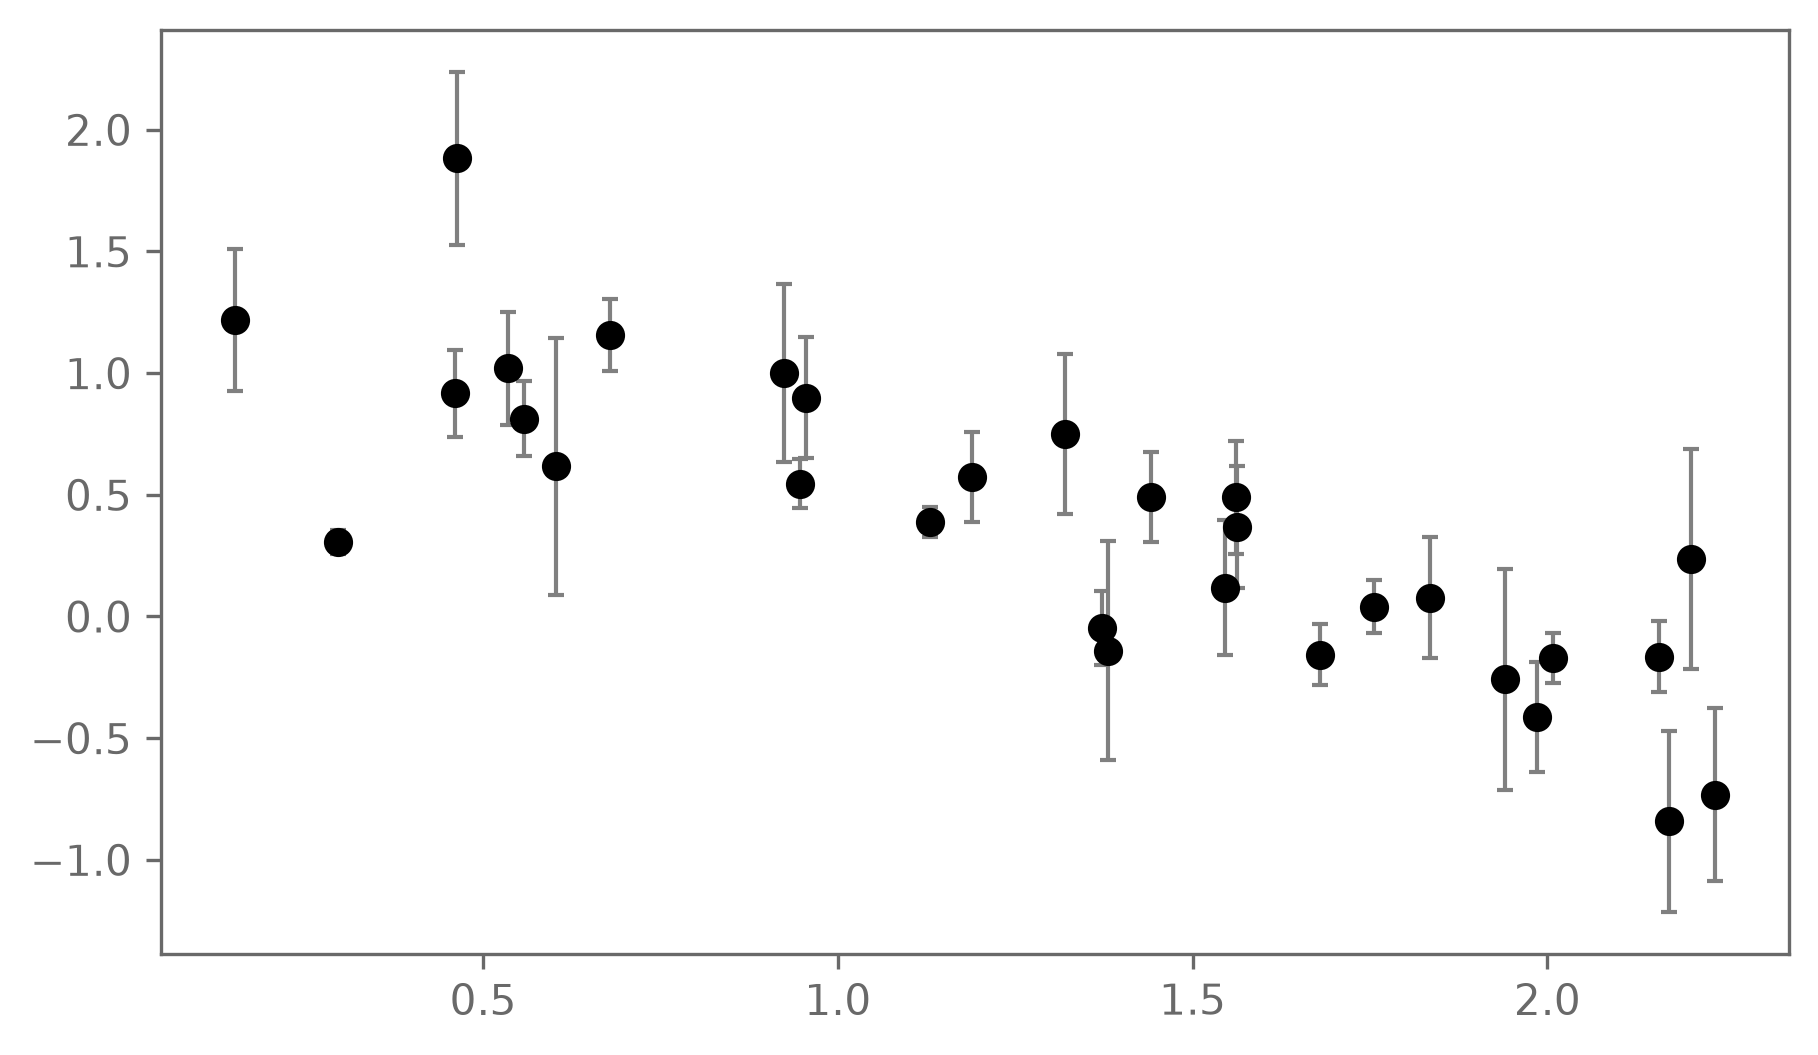

In [4]:
# plot the data

data = np.loadtxt(
    f"../lectures/data/linear_fits/data_{datanr}.txt",  
    dtype='float64'        
)

plt.figure()
plt.errorbar(data[:, 0], data[:, 1], yerr=data[:, 2], fmt='o', color='black', ecolor='gray', elinewidth=1, capsize=2)
plt.show()


In [5]:
x = data[:, 0]
y = data[:, 1]
sigma_y = data[:, 2]

#---

# The linear model
def model(m, b, x):
    return m*x + b

# Probability of the data, given the model parameters: P(y|m, b)
# We use the logarithm here for computational reasons
def log_likelihood_probability(y, m, b, x, sigma_y):
    prediction = model(m, b, x)

    n = len(y)
    # log of the PDF of a multivariate Gaussian
    return (
        -0.5 * np.sum((y - prediction)**2/sigma_y**2)  # Exponent
        -0.5 * np.sum(np.log(2*np.pi*sigma_y**2))      # Normalisation
    )
        # - n/2*np.log(2*np.pi*sigma_y**2)               # Normalisation

#---

if datanr == 0:
    m_prior = scipy.stats.norm(loc=1, scale=1)
    b_prior = scipy.stats.norm(loc=0, scale=1.2)
elif datanr == 1:
    m_prior = scipy.stats.norm(loc=-0.7, scale=0.7)
    b_prior = scipy.stats.norm(loc=1.5, scale=1)
elif datanr == 2:
    m_prior = scipy.stats.norm(loc=0.5, scale=0.5)
    b_prior = scipy.stats.norm(loc=-0.5, scale=0.5)
else:
    raise ValueError(f"Unknown datanr {datanr}")

def log_prior_probability(m, b):
    return m_prior.logpdf(m) + b_prior.logpdf(b)

#---

def sample_prior(n_sample):
    """Sample n_sample times from the prior distribution."""
    return np.vstack((m_prior.rvs(n_sample), b_prior.rvs(n_sample))).T

# Fix the pseudo random number generator seed for reproducibility
np.random.seed(42)

# Evaluate the model at the prior sample parameters
prior_model_predictive = np.array(
    [model(*parameters, x) for parameters in sample_prior(n_sample=20)]
)

#---

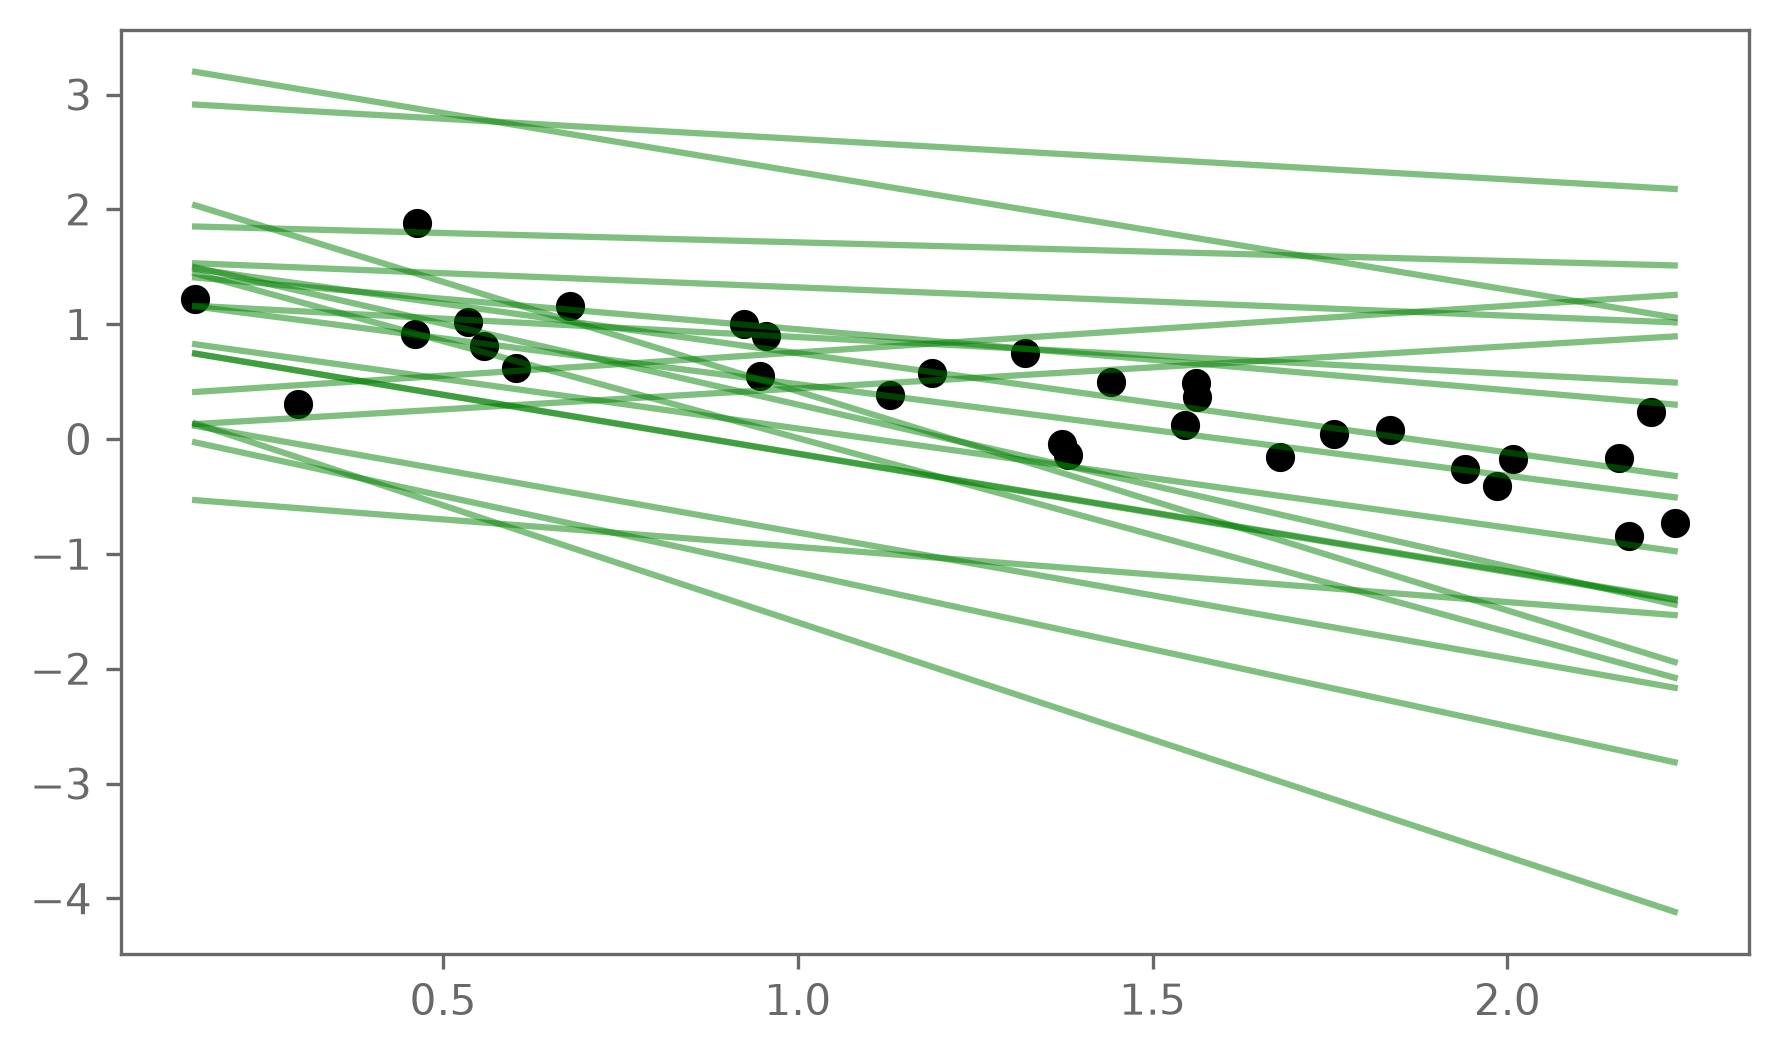

In [6]:
plt.figure()
plt.plot(x, y, 'o', color='black')
plt.plot(x, prior_model_predictive.T, color='green', alpha=0.5)
plt.show()

In [7]:
# This looks reasonable! Let us also check that data created based on these models look reasonable as well:
# Since we have a Gaussian likelihood, we can add Gaussian noise with the 
# correct variance to our prior model predictions
prior_predictive = (
    prior_model_predictive
    + sigma_y*np.random.normal(size=prior_model_predictive.shape)
)

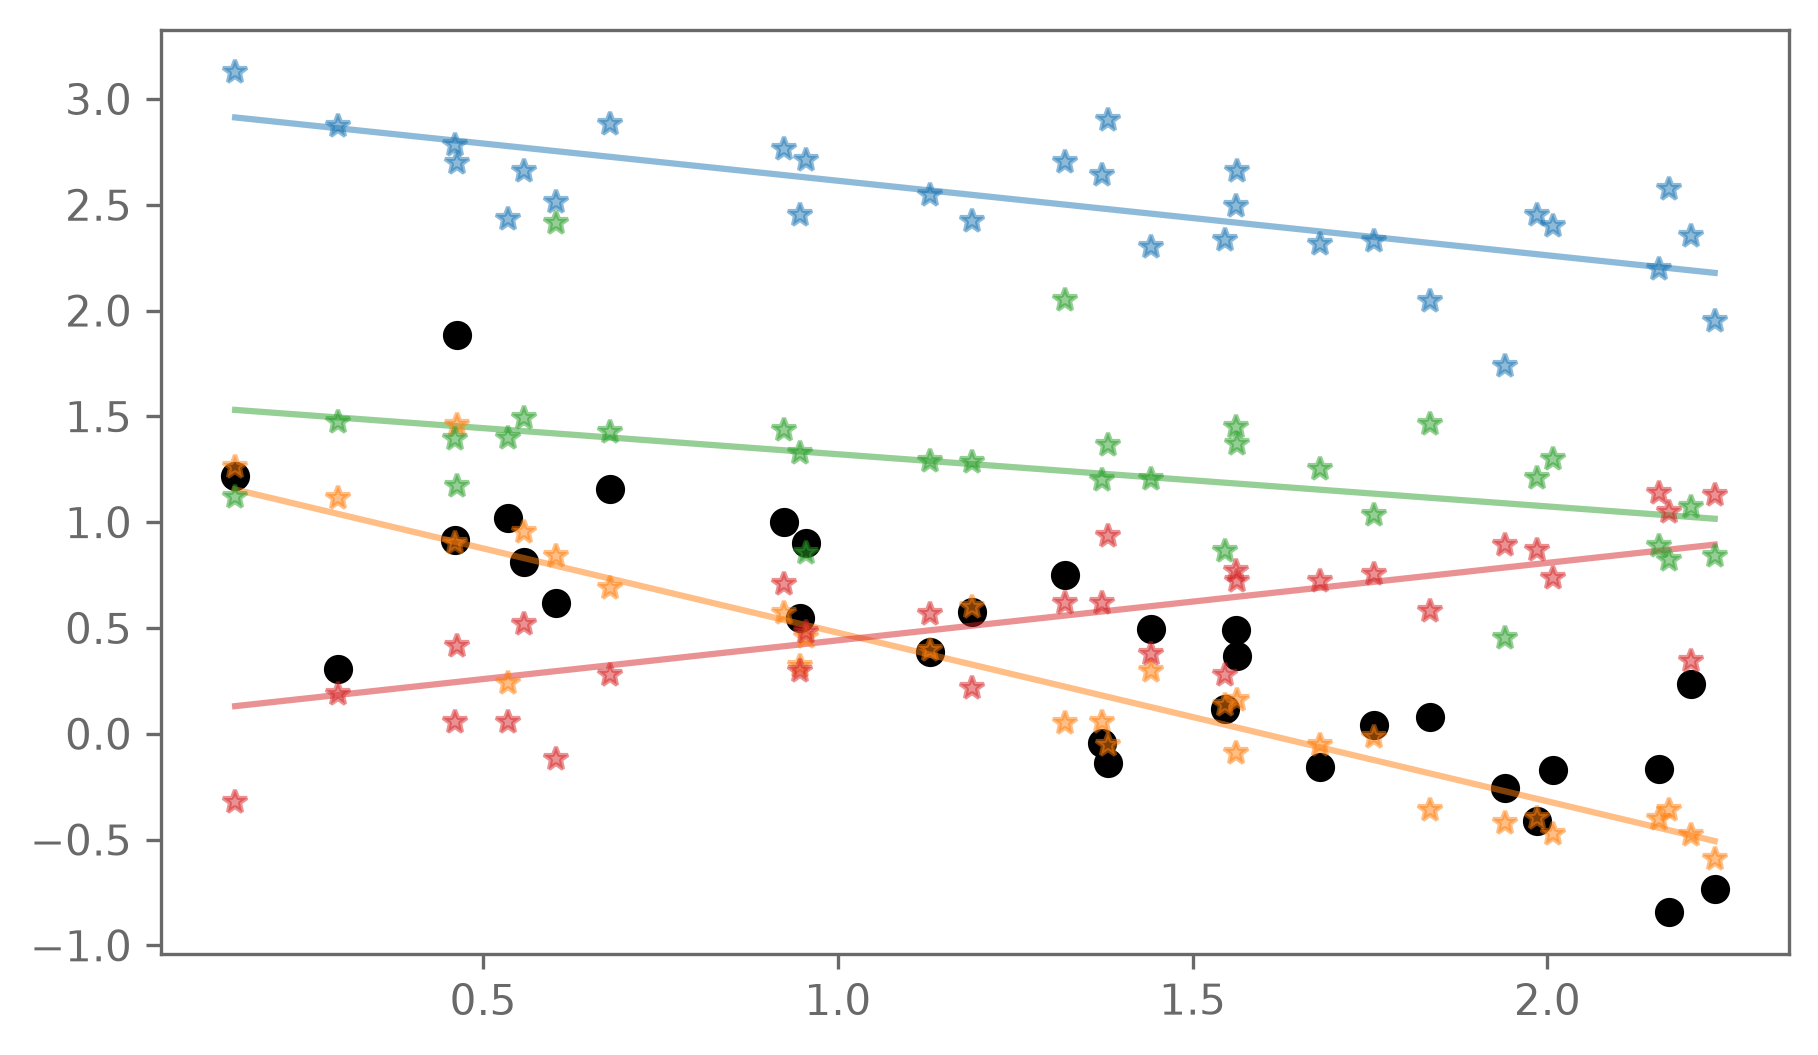

In [8]:
m = 4
plt.figure()
plt.plot(x, y, 'o', color='black')
plt.plot(x, (prior_model_predictive[:m]).T, alpha=0.5)
plt.gca().set_prop_cycle(None)
plt.plot(x, (prior_predictive[:m]).T, '*', alpha=0.5)
plt.show()

In [9]:
# fit the model

def log_posterior_probability(m, b, x, sigma_y, y):
    return (
        log_likelihood_probability(y, m, b, x, sigma_y)
        + log_prior_probability(m, b)
    )

# The scipy minimizer finds the minimum, so we need to take the 
# negative of the posterior. The scipy minimizer also passes an array 
# with the parameters, this wrapper splits this array into m and b.
def negative_log_posterior(theta, x, sigma_y, y):
    m, b = theta
    return -log_posterior_probability(m, b, x, sigma_y, y)

if datanr == 0:
    initial_guess = (1, 0)
    m_true = 1.3
    b_true = -0.2
elif datanr == 1:
    initial_guess = (-0.8, 2.)
    m_true = None
    b_true = None
else:
    initial_guess = (0.5, -0.5)
    m_true = None
    b_true = None

MAP_result = scipy.optimize.minimize(
    fun=negative_log_posterior,
    x0=initial_guess,
    args=(x, sigma_y, y)
)
m_MAP, b_MAP = MAP_result.x
# m_true = 1.3
# b_true = -0.2

print("MAP results")
print(f"m_MAP = {m_MAP:.3f}, b_MAP = {b_MAP:.3f}")
if m_true: print(f"m_true = {m_true:.3f}, b_true = {b_true:.3f}")

MAP results
m_MAP = -0.363, b_MAP = 0.701


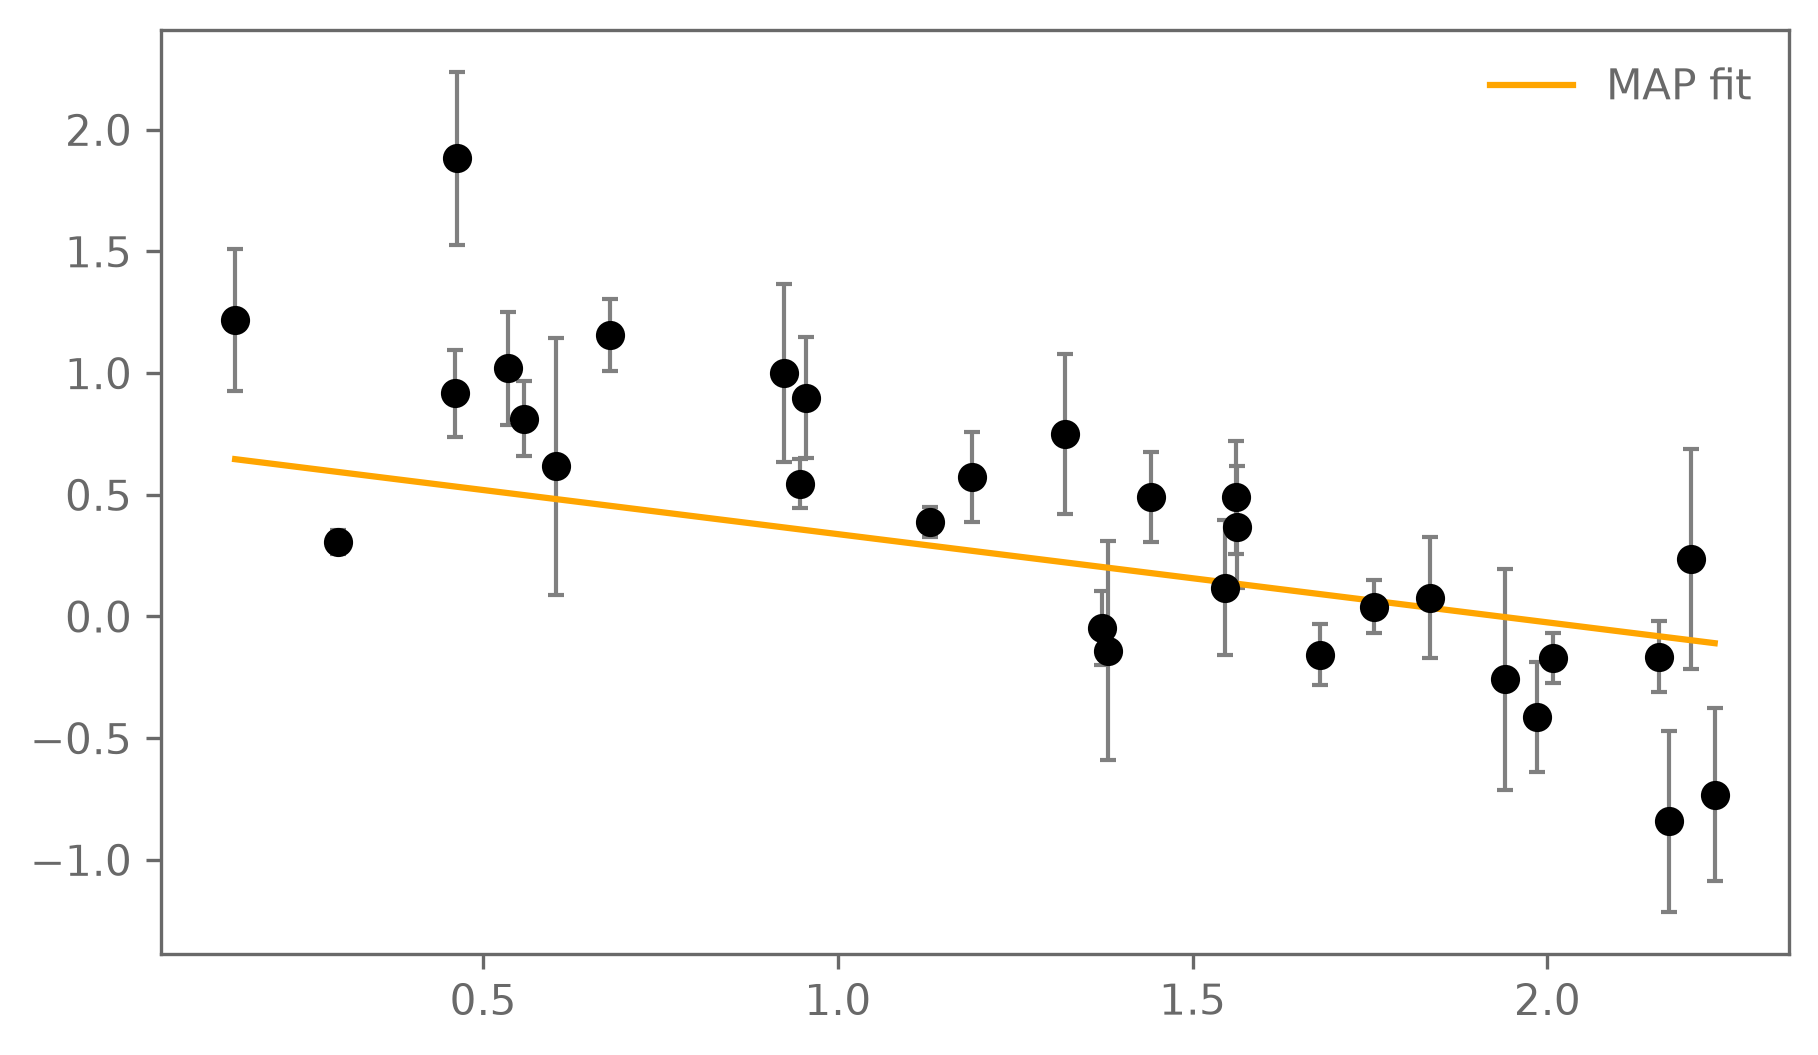

In [10]:
plt.figure()
if m_true: plt.plot(x, model(m_true, b_true, x), '--' ,color='black', label='true model', alpha=0.5)
plt.errorbar(x, y, yerr=sigma_y, fmt='o', color='black', ecolor='gray', elinewidth=1, capsize=2)
plt.plot(x, model(m_MAP, b_MAP, x), color='orange', label='MAP fit')
plt.legend()
plt.show()

In [11]:
# SAMPLING THE POSTERIOR
# The MAP only tells us about the mode of the posterior.
# In Bayesian statistics we care about the whole probability structure.
# To get there, we need to create samples from the posterior.
# We will cover the details of how and why we sample from distribution in much more detail later in the course. This is just to give you a flavour for how this works!
# In this specific example there would be an analytic expression for the posterior but in general that is not the case!

# emcee passes an array of values for the sampled parameters
# This wrapper just splits the array theta into m and b
def log_posterior_wrapper(theta, x, sigma_y, y):
    m, b = theta
    return log_posterior_probability(m, b, x, sigma_y, y)

# emcee requires some extra settings to run
n_param = 2       # Number of parameter we are sampling
n_walker = 10     # Number of walkers. This just needs to be 
                  # larger than 2*n_param + 1!
n_step = 5000     # How many steps each walker will take. The number
                  # of samples will be n_walker*n_step

# The starting point for each walker
theta_init = np.array([0.5, 0.5]) \
    + 0.1*np.random.normal(size=(n_walker, n_param))

sampler = emcee.EnsembleSampler(
    nwalkers=n_walker, ndim=n_param,
    log_prob_fn=log_posterior_wrapper,
    args=(x, sigma_y, y)
)
state = sampler.run_mcmc(theta_init, nsteps=n_step)


# The samples will be correlated, this checks how correlated they are
# We will discuss this once we come to MCMC methods
print("Auto-correlation time:")
for name, value in zip(["m", "b", "f"], sampler.get_autocorr_time()):
    print(f"{name} = {value:.1f}")

# We need to discard the beginning of the chain (a few auto-correlation times)
# to get rid of the initial conditions
chain = sampler.get_chain(discard=300, thin=10, flat=True)

Auto-correlation time:
m = 28.6
b = 27.3


In [12]:
print("Posterior results (mean±std)")
print(f"m = {np.mean(chain[:,0]):.2f}±{np.std(chain[:,0]):.2f}")
print(f"b = {np.mean(chain[:,1]):.2f}±{np.std(chain[:,1]):.2f}")

Posterior results (mean±std)
m = -0.36±0.04
b = 0.70±0.05


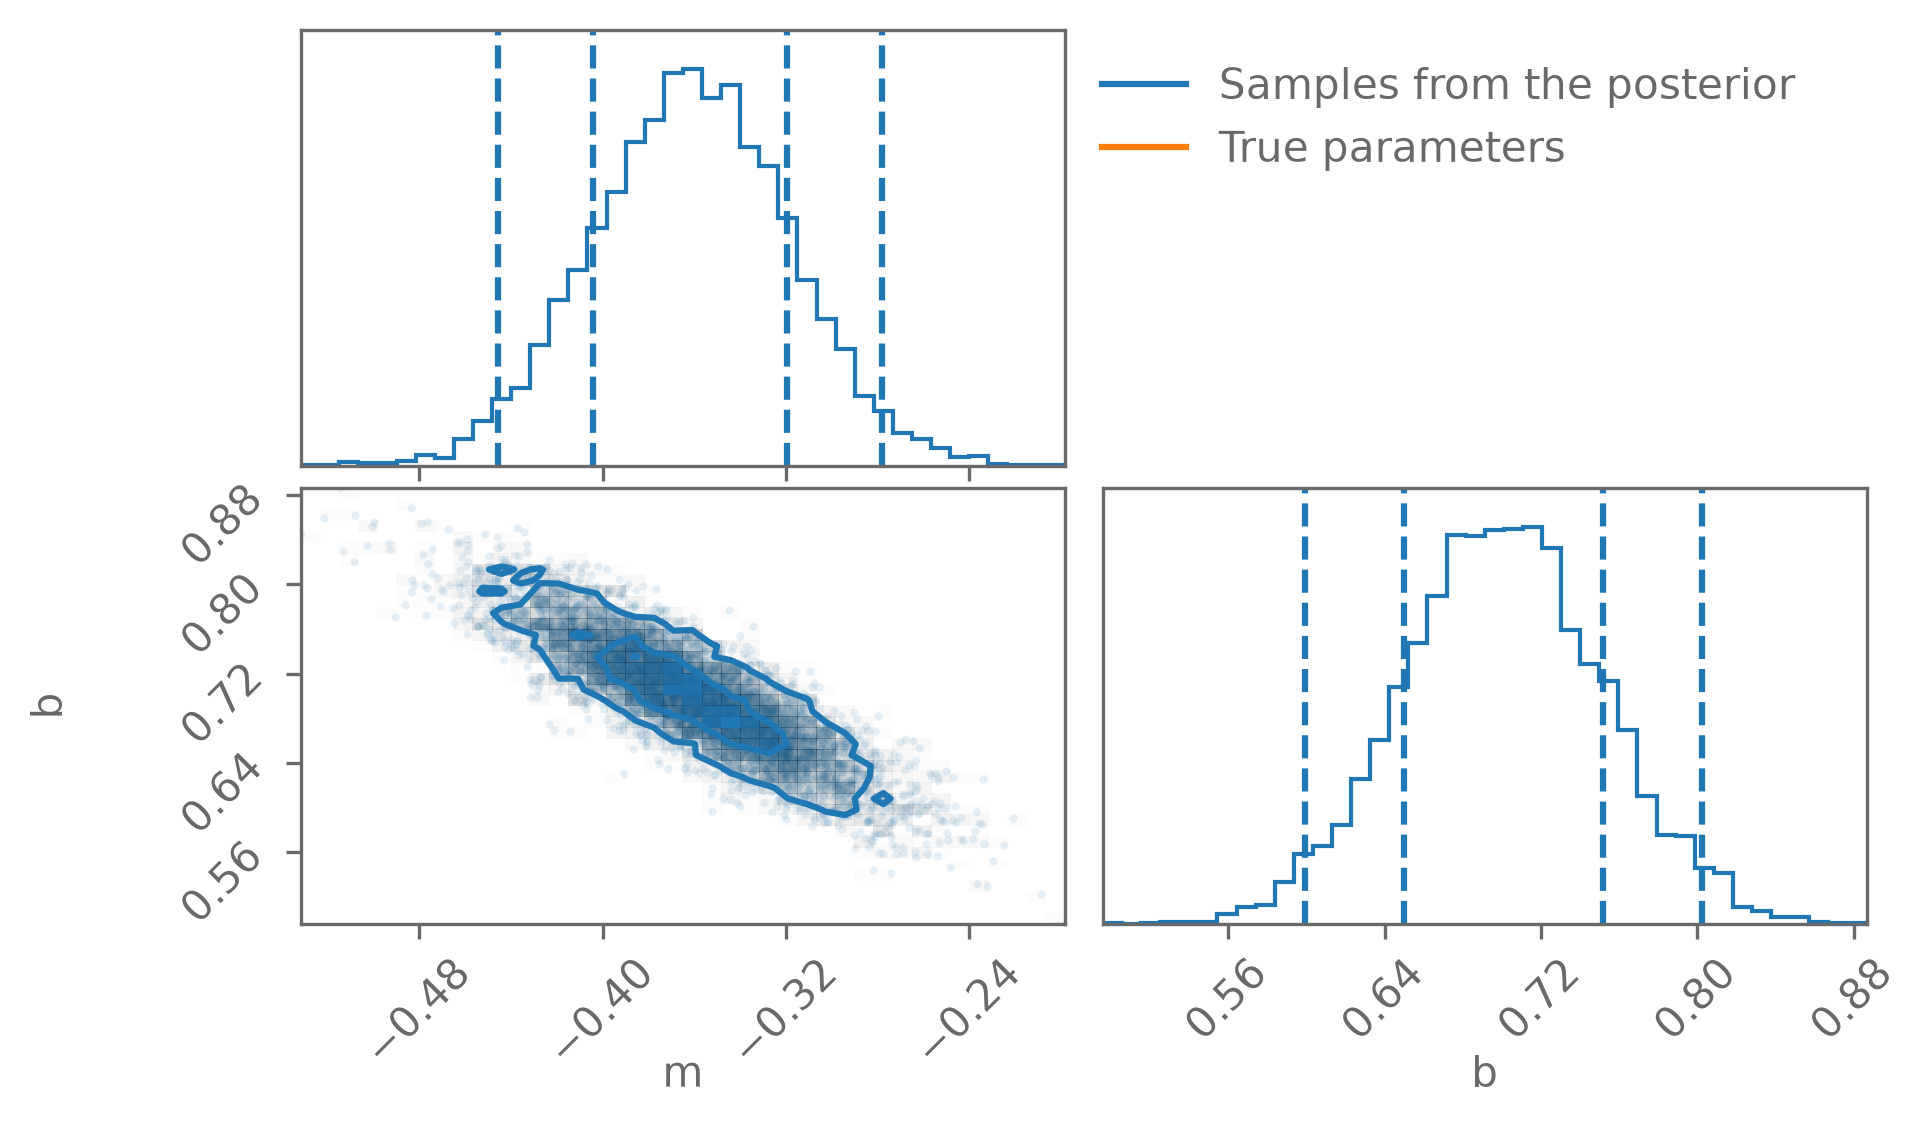

In [13]:
fig = plt.figure()
fig = corner.corner(
    chain,
    bins=40,
    labels=["m", "b"],
    color="C0",
    truths=[m_true, b_true],
    truth_color="C1",
    levels=1-np.exp(-0.5*np.array([1, 2])**2), # Credible contours corresponding
                                               # to 1 and 2 sigma in 2D
    quantiles=[0.025, 0.16, 0.84, 0.975],
    fig=fig
);
fig.get_axes()[0].plot([], [], c="C0", label="Samples from the posterior")
fig.get_axes()[0].plot([], [], c="C1", label="True parameters")
fig.get_axes()[0].legend(loc=2, bbox_to_anchor=(1, 1))
plt.show()

In [14]:
# Choose a small subsample of the chain for plotting purposes
chain_samples = chain[np.random.choice(chain.shape[0], size=200)]
# Evaluate the model at the sample parameters
model_predictive = np.array(
    [model(*sample, x) for sample in chain_samples]
)
model_quantiles = np.quantile(
    model_predictive, q=[0.025, 0.16, 0.84, 0.975], axis=0
)

In [15]:
# Because we have a Gaussian likelihood with variance \sigma_y^2, we can sample
# from the posterior predictive distribution by adding Gaussian noise with
# variance \sigma_y^2 to the model prediction samples
posterior_predictive = \
    model_predictive + sigma_y*np.random.normal(size=model_predictive.shape)

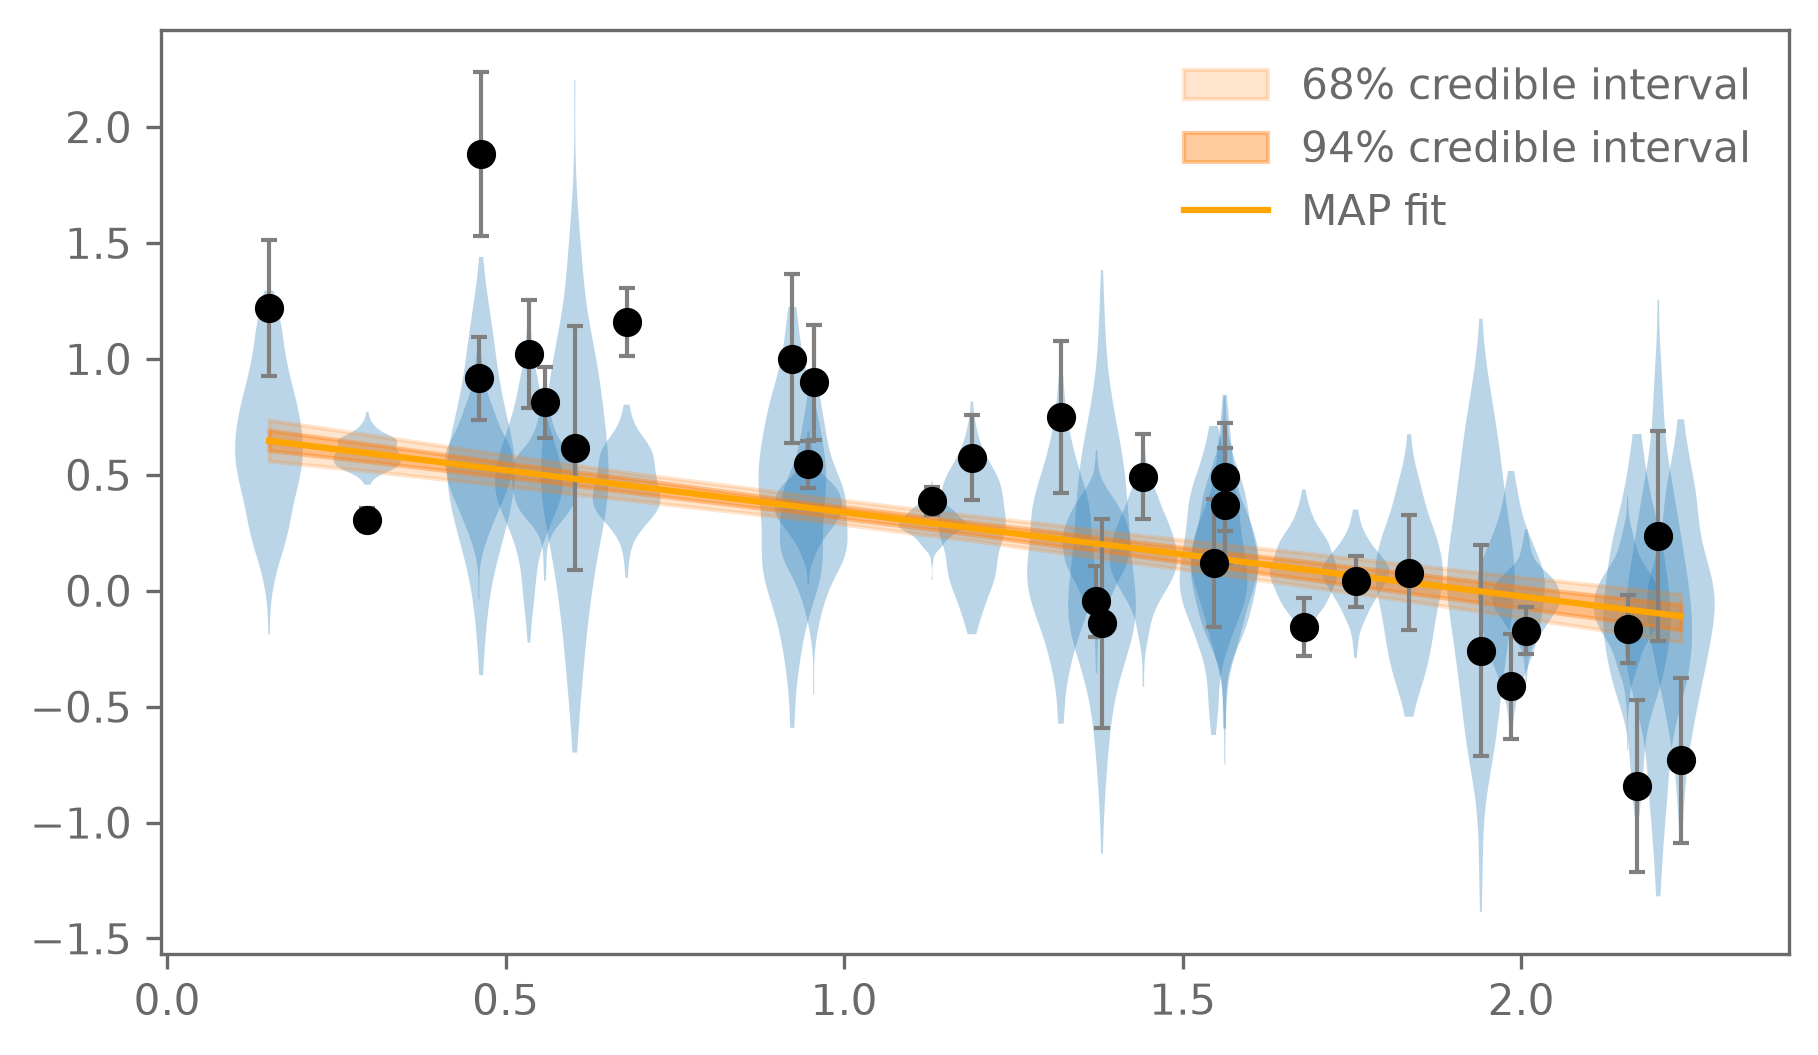

In [16]:
plt.figure()
plt.violinplot(
    posterior_predictive, positions=x, widths=0.1,
    showmeans=False, showmedians=False, showextrema=False
)
plt.errorbar(x, y, yerr=sigma_y, fmt='o', color='black', ecolor='gray', elinewidth=1, capsize=2)
for i in range(int(model_quantiles.shape[0]/2)):
    plt.fill_between(
        x, model_quantiles[i], model_quantiles[-(i+1)],
        color='C1', alpha=0.2 + 0.2*i, label=f'{int((1-2*0.16**(i+1))*100)}% credible interval'
    )
if m_true: plt.plot(x, model(m_true, b_true, x), '--' ,color='black', label='true model', alpha=0.5)
plt.plot(x, model(m_MAP, b_MAP, x), color='orange', label='MAP fit')
plt.legend()
plt.show()

# Exercise 2

The data in the previous example were a synthetic version of real observations that were obtained in an AstroWoche project in 2024 by Jonas Spiller, Theo Lequy, Clara Bleich. 

<!-- ![jovian moons data](../assets/jovian_moons_raw_data.png) -->
<img style="display: block; 
    margin-left: auto;
    margin-right: auto;
    width: 60%;"
    src="../assets/jovian_moons_raw_data.png" alt="jovian moons data"/>

The real observations can be found in `data/jovian_moons/{moon}.dat`:

In [ ]:
moon = "Io" # "Callisto", "Europa", "Ganymede", "Io", "Io_synthetic"

t, distance, distance_alt, distance_err = np.loadtxt(
    f"../lectures/data/jovian_moons/{moon}.dat", unpack=True)


1. Repeat the analysis with the real data set. What do you find?

There is another distance estimate provided. The difference between the distance estimates comes from different approaches to converting the measured distance between Jupiter and its moons from the number of pixels to a physical distance in km.

2. How does the analysis look when using this other distance estimate (what I call `distance_alt`)? What about the other moons?



Because there are two distance estimates that do not agree, both of which are based on reasonable approaches, this suggests that there might be a _systematic_ error in the measurements. Systematic errors are usually not random (which means they do not get smaller as you obtain more data). But we could pretend the offset between the two measurements is an estimate of an unaccounted statistical uncertainty. 

3. How does the analysis look when we assume `sigma_d**2 = distance_err**2 + (distance - distance_alt)**2`?



4. Instead of assuming that the uncertainty is underestimated by this offset, we can also model it. Does the model work better if the variance is a free parameter?
